# Credit Card Fraud Detection

Sebastian Smith, Xavier Leffler, Aarush Anand, Gustavo Aldrey

We want to predict whether a credit card transaction is fraud and see which features are the most useful for detecting it.

Dataset: [Credit Card Transactions Fraud Detection](https://www.kaggle.com/datasets/kartik2112/fraud-detection)

Things to keep in mind:
- Only resample the training data
- A card can only be on one side of a split
- Don't use `test_a`, `test_b` or `test_only_cards` until we have picked the final model and threshold
- Don't use `cc_num` as a feature

## Imports and Settings

In [50]:
import io
import urllib.request
import zipfile
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from sklearn.metrics import precision_score
from sklearn.model_selection import StratifiedGroupKFold, StratifiedKFold, cross_val_predict, cross_validate, train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn import feature_selection
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
SEED = 42
LOCKED_FRACTION = 0.2
N_FOLDS = 5
DATA_DIR = Path("data/raw")
DATA_URL = "https://www.kaggle.com/api/v1/datasets/download/kartik2112/fraud-detection"

In [51]:
# download the dataset if we don't have it yet
if not (DATA_DIR / "fraudTrain.csv").exists():
    DATA_DIR.mkdir(parents=True, exist_ok=True)
    with urllib.request.urlopen(DATA_URL) as response:
        archive = zipfile.ZipFile(io.BytesIO(response.read()))
    archive.extract("fraudTrain.csv", DATA_DIR)
    archive.extract("fraudTest.csv", DATA_DIR)

sorted(path.name for path in DATA_DIR.glob("*.csv"))

['fraudTest.csv', 'fraudTrain.csv']

---
# Part 1: Data and Splits

## Loading the Data

We drop the index, name, street, transaction number and unix time columns since they only identify the person or the transaction.

In [52]:
DROP = ["Unnamed: 0", "first", "last", "street", "trans_num", "unix_time"]
DATES = ["trans_date_trans_time", "dob"]

train = pd.read_csv(DATA_DIR / "fraudTrain.csv", parse_dates=DATES).drop(columns=DROP)
test = pd.read_csv(DATA_DIR / "fraudTest.csv", parse_dates=DATES).drop(columns=DROP)

train.head()

,trans_date_trans_time,cc_num,merchant,category,amt,gender,city,state,zip,lat,long,city_pop,job,dob,merch_lat,merch_long,is_fraud
0,2019-01-01 00:00:18,2703186189652095,"fraud_Rippin, Kub and Mann",misc_net,4.97,F,Moravian Falls,NC,28654,36.0788,-81.1781,3495,"Psychologist, counselling",1988-03-09,36.011293,-82.048315,0
1,2019-01-01 00:00:44,630423337322,"fraud_Heller, Gutmann and Zieme",grocery_pos,107.23,F,Orient,WA,99160,48.8878,-118.2105,149,Special educational needs teacher,1978-06-21,49.159047,-118.186462,0
2,2019-01-01 00:00:51,38859492057661,fraud_Lind-Buckridge,entertainment,220.11,M,Malad City,ID,83252,42.1808,-112.2620,4154,Nature conservation officer,1962-01-19,43.150704,-112.154481,0
3,2019-01-01 00:01:16,3534093764340240,"fraud_Kutch, Hermiston and Farrell",gas_transport,45.00,M,Boulder,MT,59632,46.2306,-112.1138,1939,Patent attorney,1967-01-12,47.034331,-112.561071,0
4,2019-01-01 00:03:06,375534208663984,fraud_Keeling-Crist,misc_pos,41.96,M,Doe Hill,VA,24433,38.4207,-79.4629,99,Dance movement psychotherapist,1986-03-28,38.674999,-78.632459,0


## Looking at the Data

In [53]:
# summary of a dataset
def describe(frame):
    times = frame["trans_date_trans_time"]
    return {
        "rows": len(frame),
        "cards": frame["cc_num"].nunique(),
        "first transaction": times.min(),
        "last transaction": times.max(),
        "fraud rows": int(frame["is_fraud"].sum()),
        "fraud rate (%)": round(100 * frame["is_fraud"].mean(), 4),
    }


# compare the two files
train_cards, test_cards = set(train["cc_num"]), set(test["cc_num"])

display(pd.DataFrame({"Kaggle train": describe(train), "Kaggle test": describe(test)}))
print("Cards in both files:", len(train_cards & test_cards))
print("Cards only in the train file:", len(train_cards - test_cards))
print("Cards only in the test file:", len(test_cards - train_cards))
print("Missing values:", int(train.isna().sum().sum() + test.isna().sum().sum()))
print("Exact duplicate rows:", int(train.duplicated().sum() + test.duplicated().sum()))

,Kaggle train,Kaggle test
rows,1296675,555719
cards,983,924
first transaction,2019-01-01 00:00:18,2020-06-21 12:14:25
last transaction,2020-06-21 12:13:37,2020-12-31 23:59:34
fraud rows,7506,2145
fraud rate (%),0.5789,0.386


Cards in both files: 908
Cards only in the train file: 75
Cards only in the test file: 16
Missing values: 0
Exact duplicate rows: 0


### Does Fraud Repeat on the Same Card?

For each transaction we find how long ago that card's last fraud was, then get the fraud rate for different time windows. This only uses the training file.

In [54]:
# sort so each card's transactions are together and in time order
ordered = train.sort_values(["cc_num", "trans_date_trans_time"])
is_fraud = ordered["is_fraud"] == 1
# time of each fraud, blank if the transaction isn't fraud
fraud_time = ordered["trans_date_trans_time"].where(is_fraud)
# for each transaction, the time of the card's most recent fraud before it
last_fraud = fraud_time.groupby(ordered["cc_num"]).transform(lambda s: s.ffill().shift())
# how long ago that fraud was
gap = ordered["trans_date_trans_time"] - last_fraud

# which transactions fall in each time window
windows = {
    "Within 1 hour": gap <= pd.Timedelta(hours=1),
    "Within 24 hours": gap <= pd.Timedelta(hours=24),
    "Within 3 days": gap <= pd.Timedelta(days=3),
    "Within 7 days": gap <= pd.Timedelta(days=7),
    "Within 30 days": gap <= pd.Timedelta(days=30),
    "Any time after (no window)": gap.notna(),
    "All transactions": pd.Series(True, index=ordered.index),
}
# fraud rate for each window
display(
    pd.DataFrame(
        [
            {
                "time since the card's last fraud": label,
                "transactions": int(rows.sum()),
                "fraud rate (%)": round(100 * is_fraud[rows].mean(), 2),
            }
            for label, rows in windows.items()
        ]
    )
)

# how many frauds came after an earlier fraud on the same card
repeat_frauds = int((is_fraud & gap.notna()).sum())
within_24_hours = int((is_fraud & windows["Within 24 hours"]).sum())
print(f"Fraud transactions after an earlier fraud on the same card: {repeat_frauds:,} of {int(is_fraud.sum()):,} ({100 * repeat_frauds / is_fraud.sum():.0f}%)")
print(f"Of those, within 24 hours of the previous fraud: {within_24_hours:,} ({100 * within_24_hours / repeat_frauds:.1f}%)")

,time since the card's last fraud,transactions,fraud rate (%)
0,Within 1 hour,3279,99.18
1,Within 24 hours,8392,80.11
2,Within 3 days,12000,56.20
3,Within 7 days,19294,34.95
4,Within 30 days,59516,11.33
5,Any time after (no window),512850,1.32
6,All transactions,1296675,0.58


Fraud transactions after an earlier fraud on the same card: 6,744 of 7,506 (90%)
Of those, within 24 hours of the previous fraud: 6,723 (99.7%)


## Splitting the Data

We set aside 20% of the cards (the locked cards) so we can test on cards the model never saw. Their transactions in the training file are not used.

- `dev`: training file without the locked cards. This is what we train and cross validate on
- `test_a`: later transactions of the locked cards (new customers)
- `test_b`: later transactions of the cards in `dev` (returning customers)
- `test_only_cards`: 16 cards that are only in the test file. All 163 of their transactions are fraud, so we keep them separate

`test_a` and `test_b` have different fraud rates, so compare each PR-AUC to its own fraud rate.

In [55]:
# pick 20% of the cards, keeping the same mix of cards with and without fraud
def choose_locked_cards(frame, fraction=LOCKED_FRACTION, seed=SEED):
    # 1 if the card had any fraud, 0 if not
    had_fraud = frame.groupby("cc_num")["is_fraud"].max().sort_index()
    _, locked = train_test_split(
        had_fraud.index.to_numpy(),
        test_size=fraction,
        stratify=had_fraud.to_numpy(),
        random_state=seed,
    )
    return np.sort(locked)


locked_cards = choose_locked_cards(train)

# training data without the locked cards
dev = train[~train["cc_num"].isin(locked_cards)].reset_index(drop=True)
# split the test file into new cards, returning cards and cards only in the test file
is_returning = test["cc_num"].isin(dev["cc_num"].unique())
test_a = test[test["cc_num"].isin(locked_cards)].reset_index(drop=True)
test_b = test[is_returning].reset_index(drop=True)
test_only_cards = test[~test["cc_num"].isin(train["cc_num"])].reset_index(drop=True)

print("Locked cards:", len(locked_cards))
print("Training-period rows discarded:", int(train["cc_num"].isin(locked_cards).sum()))
pd.DataFrame(
    {
        "dev": describe(dev),
        "test_a": describe(test_a),
        "test_b": describe(test_b),
        "test_only_cards": describe(test_only_cards),
    }
)

Locked cards: 197
Training-period rows discarded: 237855


,dev,test_a,test_b,test_only_cards
rows,1058820,101159,454397,163
cards,786,171,737,16
first transaction,2019-01-01 00:00:18,2020-06-21 12:15:17,2020-06-21 12:14:25,2020-06-24 00:26:45
last transaction,2020-06-21 12:13:37,2020-12-31 23:56:57,2020-12-31 23:59:34,2020-12-22 23:13:39
fraud rows,6010,402,1580,163
fraud rate (%),0.5676,0.3974,0.3477,100.0


## Cross Validation Folds

We use 5 folds and keep all of a card's transactions in the same fold.

In [56]:
# each card stays in one fold and the folds have about the same fraud rate
splitter = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
folds = list(splitter.split(np.zeros(len(dev)), dev["is_fraud"], groups=dev["cc_num"]))

# see how balanced the folds are
pd.DataFrame(
    [
        {
            "fold": number,
            "validation rows": len(val_pos),
            "validation cards": dev["cc_num"].iloc[val_pos].nunique(),
            "validation fraud rows": int(dev["is_fraud"].iloc[val_pos].sum()),
            "validation fraud rate (%)": round(100 * dev["is_fraud"].iloc[val_pos].mean(), 4),
        }
        for number, (_, val_pos) in enumerate(folds)
    ]
)

,fold,validation rows,validation cards,validation fraud rows,validation fraud rate (%)
0,0,211503,157,1199,0.5669
1,1,212154,159,1205,0.5680
2,2,211802,156,1199,0.5661
3,3,211475,157,1206,0.5703
4,4,211886,157,1201,0.5668


## Checking the Splits

This cell makes sure no card ends up on both sides of a split.

In [57]:
# stops with an error if the splits break any of our rules
def check_splits(dev, test_a, test_b, folds, locked_cards):
    dev_cards = set(dev["cc_num"])
    locked = {int(card) for card in locked_cards}

    # locked cards and test_a cards can't be in dev, test_b cards have to be
    assert not dev_cards & locked, "A locked card has rows in dev."
    assert not dev_cards & set(test_a["cc_num"]), "A Test A card has rows in dev."
    assert set(test_b["cc_num"]) <= dev_cards, "A Test B card is missing from dev."

    # no card can be in both train and validation in any fold
    cards = dev["cc_num"].to_numpy()
    all_val = []
    for fold, (train_pos, val_pos) in enumerate(folds):
        shared = set(cards[train_pos]) & set(cards[val_pos])
        assert not shared, f"Fold {fold}: {len(shared)} cards are in train and validation."
        assert len(train_pos) + len(val_pos) == len(dev), f"Fold {fold} does not cover dev."
        all_val.append(val_pos)

    # every dev row has to be validated exactly once
    val_counts = pd.Series(np.concatenate(all_val)).value_counts()
    assert len(val_counts) == len(dev), "Some dev rows are never validated."
    assert (val_counts == 1).all(), "Some dev rows are validated more than once."


# run the checks
check_splits(dev, test_a, test_b, folds, locked_cards)
# test_a should only have locked cards
assert test_a["cc_num"].isin(locked_cards).all(), "A Test A card is not locked."
# the three test groups should add up to the whole test file
assert len(test_a) + len(test_b) + len(test_only_cards) == len(test), "A test row is missing or duplicated."
# we should get the same locked cards if the rows are in a different order
reshuffled = train.sample(frac=1, random_state=3)
assert np.array_equal(locked_cards, choose_locked_cards(reshuffled)), "Locked cards are not reproducible."
print("All split checks passed.")

All split checks passed.


## Random Split vs Split by Card

We compare a normal random split with our split by card to see how much it changes the scores. Both use the same features and decision trees with no resampling.

These are just basic features, so the scores will change once we have the final models. The next cell takes a few minutes to run.

In [58]:
# basic features for this comparison
def make_features(frame):
    times = frame["trans_date_trans_time"]
    return pd.DataFrame(
        {
            "amt": frame["amt"],
            "hour": times.dt.hour,
            "day_of_week": times.dt.day_of_week,
            "age": (times - frame["dob"]).dt.days / 365.25,
            "city_pop": frame["city_pop"],
            "lat": frame["lat"],
            "long": frame["long"],
            "merch_lat": frame["merch_lat"],
            "merch_long": frame["merch_long"],
            "category": frame["category"].astype("category").cat.codes,
            "gender": frame["gender"].astype("category").cat.codes,
        }
    ).to_numpy(dtype=np.float32)


X_dev = make_features(dev)
y_dev = dev["is_fraud"].to_numpy()

# the two ways of splitting and the two trees we compare
splits = {
    "random": StratifiedKFold(N_FOLDS, shuffle=True, random_state=SEED),
    "by card": folds,
}
models = {
    "depth 10": DecisionTreeClassifier(max_depth=10, random_state=SEED),
    "unlimited depth": DecisionTreeClassifier(random_state=SEED),
}
scoring = ["average_precision", "precision", "recall", "f1"]

# cross validate each tree with each split
rows = []
for model_name, model in models.items():
    for split_name, cv in splits.items():
        results = cross_validate(model, X_dev, y_dev, cv=cv, scoring=scoring)
        for fold in range(N_FOLDS):
            rows.append(
                {
                    "model": model_name,
                    "split": split_name,
                    "fold": fold,
                    "PR-AUC": results["test_average_precision"][fold],
                    "precision": results["test_precision"][fold],
                    "recall": results["test_recall"][fold],
                    "F1": results["test_f1"][fold],
                }
            )

fold_results = pd.DataFrame(rows)
fold_results.round(4)

,model,split,fold,PR-AUC,precision,recall,F1
0,depth 10,random,0,0.8342,0.9357,0.7754,0.8480
1,depth 10,random,1,0.8713,0.9419,0.8095,0.8707
2,depth 10,random,2,0.8548,0.9341,0.7903,0.8562
3,depth 10,random,3,0.8620,0.9442,0.8028,0.8678
4,depth 10,random,4,0.8596,0.9400,0.7945,0.8611
5,depth 10,by card,0,0.8330,0.9053,0.7973,0.8479
6,depth 10,by card,1,0.3060,0.3713,0.7743,0.5019
7,depth 10,by card,2,0.8456,0.9462,0.7781,0.8540
8,depth 10,by card,3,0.8408,0.9402,0.7819,0.8538
9,depth 10,by card,4,0.8550,0.9267,0.8002,0.8588


In [59]:
metrics = ["PR-AUC", "precision", "recall", "F1"]
# average and standard deviation across folds
print("Average across the 5 folds")
display(fold_results.groupby(["model", "split"])[metrics].mean().round(4))

print("Standard deviation across the 5 folds")
display(fold_results.groupby(["model", "split"])[metrics].std().round(4))

# PR-AUC without the worst by card fold
comparison = {}
for model_name in models:
    subset = fold_results[fold_results["model"] == model_name]
    by_card = subset[subset["split"] == "by card"]["PR-AUC"]
    comparison[model_name] = {
        "random": subset[subset["split"] == "random"]["PR-AUC"].mean(),
        "by card": by_card.mean(),
        "by card, lowest fold left out": by_card.drop(by_card.idxmin()).mean(),
    }
display(pd.DataFrame(comparison).T.round(3))

# false alarms per fold for the depth 10 tree split by card
predictions = cross_val_predict(models["depth 10"], X_dev, y_dev, cv=folds)
cards = dev["cc_num"].to_numpy()

rows = []
for number, (_, val_pos) in enumerate(folds):
    fold_predictions, fold_truth, fold_cards = predictions[val_pos], y_dev[val_pos], cards[val_pos]
    per_card = pd.Series(fold_cards[(fold_predictions == 1) & (fold_truth == 0)]).value_counts()
    other_cards = fold_cards != per_card.index[0]
    rows.append(
        {
            "fold": number,
            "false alarms": int(per_card.sum()),
            "false alarms on worst card": int(per_card.iloc[0]),
            "precision": precision_score(fold_truth, fold_predictions),
            "precision without worst card": precision_score(fold_truth[other_cards], fold_predictions[other_cards]),
        }
    )

pd.DataFrame(rows).round(3)

Average across the 5 folds


PR-AUC  precision  recall      F1
model           split                                     
depth 10        by card  0.7361     0.8179  0.7864  0.7833
                random   0.8564     0.9392  0.7945  0.8608
unlimited depth by card  0.5512     0.6710  0.8187  0.7240
                random   0.6701     0.8126  0.8235  0.8179

Standard deviation across the 5 folds


PR-AUC  precision  recall      F1
model           split                                     
depth 10        by card  0.2405     0.2502  0.0117  0.1573
                random   0.0138     0.0042  0.0130  0.0091
unlimited depth by card  0.1570     0.1891  0.0105  0.1399
                random   0.0097     0.0126  0.0058  0.0059

,random,by card,"by card, lowest fold left out"
depth 10,0.856,0.736,0.844
unlimited depth,0.670,0.551,0.621


,fold,false alarms,false alarms on worst card,precision,precision without worst card
0,0,100,9,0.905,0.913
1,1,1580,1516,0.371,0.935
2,2,53,4,0.946,0.950
3,3,60,4,0.940,0.943
4,4,76,5,0.927,0.931


### Results

- 90% of fraud transactions come after an earlier fraud on the same card. About 80% of transactions within 24 hours of a fraud are also fraud, compared to 0.58% overall.
- With a random split, the card for every validation fraud is also in training. With the split by card, none of them are.
- The random split scores about 12 PR-AUC points higher on average, but almost all of that comes from one fold.
- In that fold, one card causes almost all of the false alarms. Without that fold the gap is about 1 point for the depth 10 tree and 5 points for the unlimited depth tree.
- The random split doesn't show this problem because the model has already seen that card's normal transactions.

---
# Part 2: Features and Exploration

We add hour, day and age, then look at which features are related to fraud. Everything here only uses `dev`.

In [60]:
def add_features(frame):
    times = frame['trans_date_trans_time']
    frame = frame.assign(
        hour=times.dt.hour,
        day=times.dt.day_of_week,
        age=(times - frame["dob"]).dt.days / 365.25
    )
    return frame[frame.columns.drop("is_fraud").tolist() + ["is_fraud"]]


dev = add_features(dev)
test_a = add_features(test_a)
test_b = add_features(test_b)
test_only_cards = add_features(test_only_cards)
print(dev.head(1))

  trans_date_trans_time            cc_num                    merchant  \
0   2019-01-01 00:00:18  2703186189652095  fraud_Rippin, Kub and Mann   

   category   amt gender            city state    zip      lat     long  \
0  misc_net  4.97      F  Moravian Falls    NC  28654  36.0788 -81.1781   

   city_pop                        job        dob  merch_lat  merch_long  \
0      3495  Psychologist, counselling 1988-03-09  36.011293  -82.048315   

   hour  day        age  is_fraud  
0     0    1  30.814511         0  


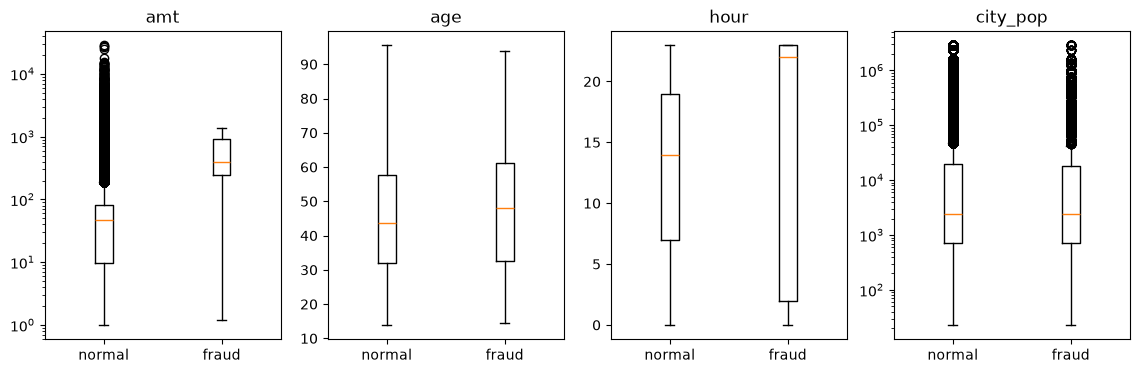

In [61]:
boxplot_dic = {}
for num_feat in ['amt', 'age', 'hour', 'city_pop']:
    non_fraud_feat = dev[dev['is_fraud'] == 0][num_feat]
    fraud_feat = dev[dev['is_fraud'] == 1][num_feat]
    boxplot_dic[num_feat] = (non_fraud_feat, fraud_feat)

fig, axes = plt.subplots(1, 4, figsize=(14, 4))
for ax, (feat, (non_fraud_feat, fraud_feat)) in zip(axes, boxplot_dic.items()):
    if feat in ['amt', 'city_pop']:
        ax.set_yscale('log')
    ax.boxplot([non_fraud_feat, fraud_feat])
    ax.set_xticks([1, 2], ['normal', 'fraud'])
    ax.set_title(feat)
plt.show()

**What the box plots show**
- `amt`: fraud is usually much larger (about $400 vs $50) and stays under about $1,400. Strong signal.
- `hour`: fraud happens mostly late at night (about 10pm to 3am). The box plot splits this across both ends because hours wrap around, so the bar chart shows it better.
- `age`: fraud victims are slightly older, but the boxes overlap a lot. Weak signal.
- `city_pop`: no difference between fraud and normal.

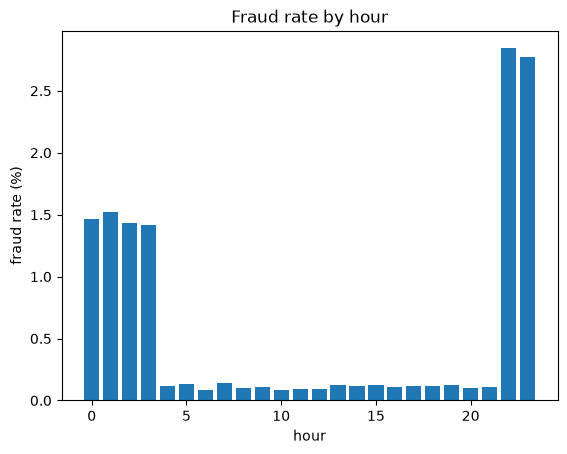

In [62]:
hourly_fraud = dev.groupby('hour')['is_fraud'].mean() * 100
plt.bar(hourly_fraud.index, hourly_fraud)
plt.xlabel("hour")
plt.ylabel("fraud rate (%)")
plt.title("Fraud rate by hour")
plt.show()

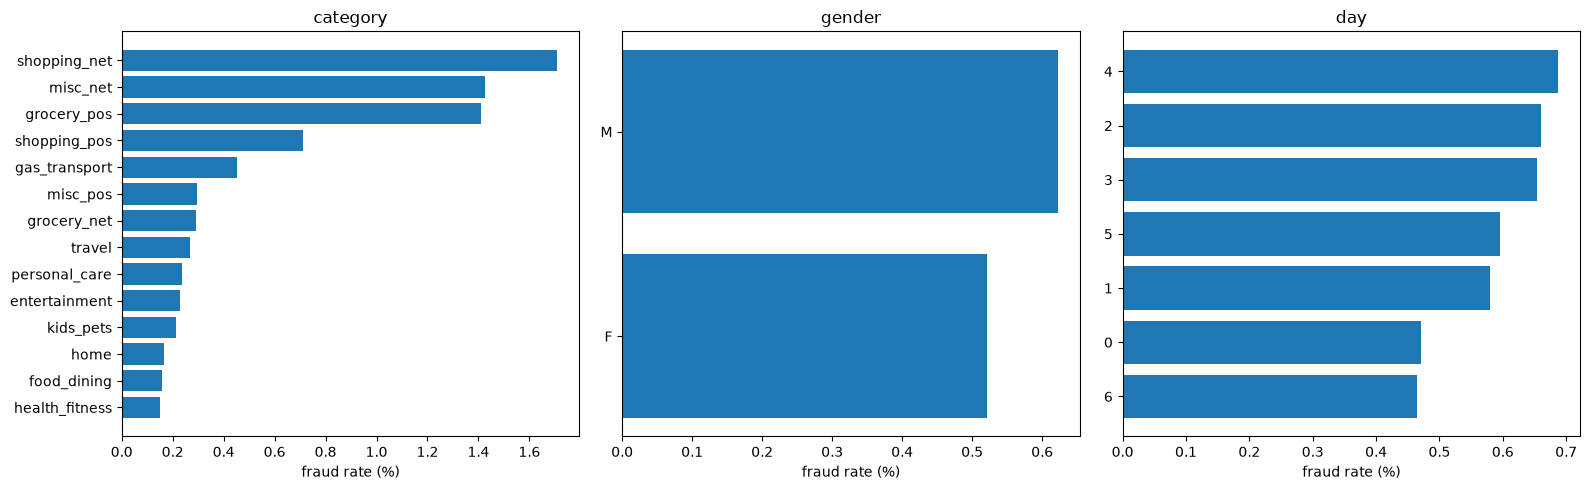

In [63]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, feat in zip(axes, ['category', 'gender', 'day']):
    rates = dev.groupby(feat)['is_fraud'].mean().sort_values() * 100
    ax.barh(rates.index.astype(str), rates)
    ax.set_title(feat)
    ax.set_xlabel('fraud rate (%)')
plt.tight_layout()
plt.show()

**What the category charts show**
- `category`: the strongest of the three. Online shopping (`shopping_net`), `misc_net` and `grocery_pos` have fraud rates of 1.4 to 1.7%, about 3 times the average of 0.57%. Most other categories are under 0.3%.
- `gender`: men are slightly higher (0.62% vs 0.52%). Weak signal.
- `day` (0 = Monday): Wednesday to Friday are highest (about 0.65%), Sunday and Monday lowest (about 0.47%). Weak signal.

In [64]:
numeric = ['amt', 'age', 'hour', 'city_pop', 'lat', 'long', 'merch_lat', 'merch_long']
dev[numeric].corr().round(2)

,amt,age,hour,city_pop,lat,long,merch_lat,merch_long
amt,1.00,-0.01,-0.02,0.01,-0.00,0.00,-0.00,0.00
age,-0.01,1.00,-0.18,-0.08,0.07,-0.01,0.07,-0.01
hour,-0.02,-0.18,1.00,0.02,-0.01,-0.01,-0.01,-0.01
city_pop,0.01,-0.08,0.02,1.00,-0.14,-0.08,-0.14,-0.08
lat,-0.00,0.07,-0.01,-0.14,1.00,-0.03,0.99,-0.03
long,0.00,-0.01,-0.01,-0.08,-0.03,1.00,-0.03,1.00
merch_lat,-0.00,0.07,-0.01,-0.14,0.99,-0.03,1.00,-0.03
merch_long,0.00,-0.01,-0.01,-0.08,-0.03,1.00,-0.03,1.00


**Correlation between numeric features**
- `merch_lat` and `merch_long` are almost the same as `lat` and `long` (0.99 and 1.00), because merchants are placed near the cardholder's home. They add little new information.
- All other pairs are close to 0, so the other features don't overlap.

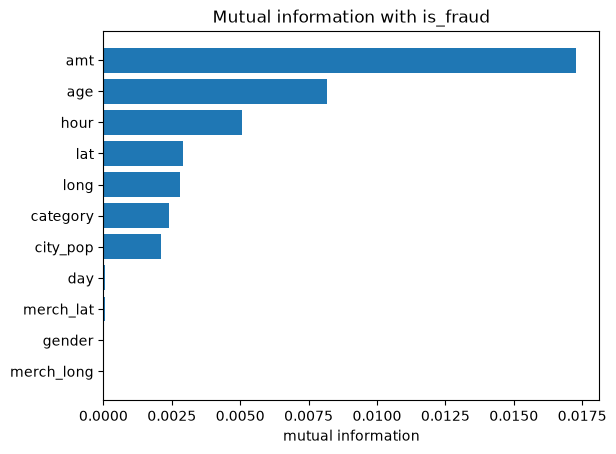

In [65]:
sample = dev.sample(200_000, random_state=SEED)
features = ['amt', 'age', 'hour', 'day', 'city_pop', 'lat', 'long', 'merch_lat', 'merch_long', 'category', 'gender']
continuous = ['amt', 'lat', 'long', 'merch_lat', 'merch_long', 'age', 'city_pop']
X_sample = sample[features]
X_sample['category'] = X_sample['category'].astype('category').cat.codes
X_sample['gender'] = X_sample['gender'].astype('category').cat.codes
y_sample = sample['is_fraud']
discrete = [feat not in continuous for feat in features]
mi_scores = feature_selection.mutual_info_classif(X_sample, y_sample, discrete_features=discrete, random_state=SEED)
mutual_info = pd.Series(mi_scores, index=features).sort_values()
plt.barh(mutual_info.index, mutual_info)
plt.xlabel('mutual information')
plt.title('Mutual information with is_fraud')
plt.show()

**Mutual information results**
- `amt` is by far the strongest, then `age` and `hour`.
- `lat`, `long`, `category` and `city_pop` help a little.
- `day`, `gender`, `merch_lat` and `merch_long` are close to 0.
- `age`, `lat`, `long` and `city_pop` are the same for every transaction on a card, so they might score high because they recognize the card rather than a real fraud pattern.

**Preprocessing**

We scale the numeric columns and one-hot encode `category` and `gender`. The preprocessor is not fit here. In Parts 3 and 4 it goes first in the pipeline, so it only gets fit on the training folds. Use `X_dev` and `y_dev` with `cv=folds`.

We leave out `merchant`, `city`, `state`, `zip` and `job` since they have too many different values to one-hot encode, and `lat` and `long` already give the location. `cc_num` is only used for the splits.

In [66]:
categorical = ['category', 'gender']
numeric = [feat for feat in features if feat not in categorical]

# scale the numeric columns and one-hot encode the categories
preprocessor = ColumnTransformer([
    ('scale', StandardScaler(), numeric),
    ('onehot', OneHotEncoder(handle_unknown='ignore'), categorical),
])

X_dev = dev[features]
y_dev = dev['is_fraud']

---
# Part 3: Imbalance and Evaluation

To do: build the pipeline with resampling only on the training folds. Add the metrics. Compare SMOTE before the split and inside the folds. Compare no resampling, SMOTE, undersampling and class weights. Pick the threshold.

---
# Part 4: Models and PCA

To do: run the dummy baseline, KNN, decision tree and Naive Bayes. Compare with and without PCA, including runtime.

---
# Final Test

To do: run this once after we pick the final model and threshold. Report `test_a` and `test_b`, and compare each to its own fraud rate. Report `test_only_cards` separately.